In [25]:
from util import make_dir_modules_importable
make_dir_modules_importable()

Adding: D:\Documents\Ciencias de datos\Ciencia de datos 2\PRACTICAS\uasd-ds-2\unidad02\LAB07\src to sys.path


In [26]:
#built-in modeules
import importlib
import argparse
import json
import os
import platform
import random
from pathlib import Path
from statistics import median, stdev
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score

#custom modules
import lab07.runtime as runtime_module
import lab07.data as data_module
import lab07.models as models_module
import util as util_module

importlib.reload(runtime_module)
importlib.reload(data_module)
importlib.reload(models_module)
importlib.reload(util_module)

#custom modules types
from lab07.runtime import check_runtime
from lab07.data import CLASS_NAMES, normalize_images, validate_images
from lab07.models import build_cnn, build_dense


In [27]:
print(check_runtime())


    - Python/OS: 3.13.14 Windows-11-10.0.26300-SP0
    - TensorFlow: 2.21.0
    - GPU: []
    


In [28]:
from util import ROOT
SEED = 42
INFERENCE_BATCH = 1000
INFERENCE_REPEATS = 5
os.environ.setdefault("TF_DETERMINISTIC_OPS", "1")
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [36]:
def compile_model(model):
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def describe_split(name: str, images: np.ndarray, labels: np.ndarray) -> dict:
    counts = np.bincount(labels, minlength=len(CLASS_NAMES)).tolist()
    print(f"{name}: x={images.shape} y={labels.shape} clases={len(np.unique(labels))} distribución={counts}")
    return {"shape": list(images.shape), "class_counts": counts}


def time_inference(model, batch: np.ndarray) -> dict:
    model.predict(batch, verbose=0)  # calentamiento: excluye trazado del grafo
    runs = []
    for _ in range(INFERENCE_REPEATS):
        start = perf_counter()
        model.predict(batch, verbose=0)
        runs.append(1000 * (perf_counter() - start) / len(batch))
    return {"median_ms_per_image": median(runs), "std_ms_per_image": stdev(runs), "runs_ms_per_image": runs}

def make_out_dirs():
    reports = ROOT / "reports"
    models_dir = ROOT / "models"
    reports.mkdir(exist_ok=True)
    models_dir.mkdir(exist_ok=True)
    return (reports, models_dir)

def get_environment_spec(epochs):
    environment = {
        "python": platform.python_version(),
        "tensorflow": tf.__version__,
        "platform": platform.platform(),
        "processor": platform.processor() or platform.machine(),
        "cpu_count": os.cpu_count(),
        "gpus": [device.name for device in tf.config.list_physical_devices("GPU")],
        "epochs": epochs,
        "seed": SEED,
    }
    return environment

def run(epochs=8) -> None:
    (reports, models_dir) = make_out_dirs()

    (x_train_all, y_train_all), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
    x_train_all = normalize_images(x_train_all)
    x_test = normalize_images(x_test)
    x_train, y_train = x_train_all[:-6000], y_train_all[:-6000]
    x_valid, y_valid = x_train_all[-6000:], y_train_all[-6000:]
    validate_images(x_train, y_train)
    validate_images(x_test, y_test)
    dataset = {
        "train": describe_split("train", x_train, y_train),
        "valid": describe_split("valid", x_valid, y_valid),
        "test": describe_split("test", x_test, y_test),
    }
    
    environment = get_environment_spec(epochs)
    print("Entorno:", json.dumps(environment))

    inference_batch = x_test[:INFERENCE_BATCH]
    metrics = {}
    trained = {}
    for name, factory in {"dense": build_dense, "cnn": build_cnn}.items():
        model = compile_model(factory(tf))
        model_path = models_dir / f"best_{name}.keras"
        callbacks = [
            tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True),
            tf.keras.callbacks.ModelCheckpoint(model_path, save_best_only=True),
        ]
        start = perf_counter()
        history = model.fit(x_train, y_train, validation_data=(x_valid, y_valid), epochs=epochs,
                            batch_size=128, callbacks=callbacks, verbose=2)
        train_seconds = perf_counter() - start
        predictions = model.predict(x_test, verbose=0).argmax(axis=1)
        report = classification_report(y_test, predictions, target_names=CLASS_NAMES, digits=3, output_dict=True)
        metrics[name] = {
            "f1_macro": float(f1_score(y_test, predictions, average="macro")),
            "accuracy": float(report["accuracy"]),
            "per_class": {label: {k: report[label][k] for k in ("precision", "recall", "f1-score")}
                          for label in CLASS_NAMES},
            "parameters": int(model.count_params()),
            "model_file_kb": model_path.stat().st_size / 1024,
            "epochs_run": len(history.history["loss"]),
            "history": {key: [float(v) for v in values] for key, values in history.history.items()},
            "train_seconds": train_seconds,
            "inference": time_inference(model, inference_batch),
        }
        trained[name] = predictions
        print(name, json.dumps({k: v for k, v in metrics[name].items() if k not in ("per_class", "history")},
                               indent=2))
        print(classification_report(y_test, predictions, target_names=CLASS_NAMES, digits=3))
    predictions = trained["cnn"]
    figure, axis = plt.subplots(figsize=(9, 8))
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=CLASS_NAMES, cmap="Blues",
                                            xticks_rotation=45, ax=axis)
    figure.savefig(reports / "confusion_cnn.png", dpi=170, bbox_inches="tight")
    wrong = np.where(predictions != y_test)[0][:16]
    figure, axes = plt.subplots(4, 4, figsize=(9, 9))
    for axis, index in zip(axes.ravel(), wrong):
        axis.imshow(x_test[index].squeeze(), cmap="gray")
        axis.set_title(f"#{index}\nR: {CLASS_NAMES[y_test[index]]}\nP: {CLASS_NAMES[predictions[index]]}", fontsize=9)
        axis.axis("off")
    figure.tight_layout()
    figure.savefig(reports / "cnn_errors.png", dpi=170)
    output = {**metrics, "dataset": dataset, "environment": environment,
              "inference_protocol": f"median of {INFERENCE_REPEATS} runs on the same {INFERENCE_BATCH}-image test batch"}
    (reports / "cv_metrics.json").write_text(json.dumps(output, indent=2), encoding="utf-8")


train: x=(54000, 28, 28, 1) y=(54000,) clases=10 distribución=[5370, 5416, 5398, 5395, 5367, 5409, 5435, 5445, 5384, 5381]
valid: x=(6000, 28, 28, 1) y=(6000,) clases=10 distribución=[630, 584, 602, 605, 633, 591, 565, 555, 616, 619]
test: x=(10000, 28, 28, 1) y=(10000,) clases=10 distribución=[1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Entorno: {"python": "3.13.14", "tensorflow": "2.21.0", "platform": "Windows-11-10.0.26300-SP0", "processor": "Intel64 Family 6 Model 141 Stepping 1, GenuineIntel", "cpu_count": 16, "gpus": [], "epochs": 8, "seed": 42}
Epoch 1/8
422/422 - 2s - 4ms/step - accuracy: 0.7903 - loss: 0.6123 - val_accuracy: 0.8415 - val_loss: 0.4494
Epoch 2/8
422/422 - 1s - 2ms/step - accuracy: 0.8498 - loss: 0.4294 - val_accuracy: 0.8540 - val_loss: 0.4073
Epoch 3/8
422/422 - 1s - 2ms/step - accuracy: 0.8618 - loss: 0.3915 - val_accuracy: 0.8590 - val_loss: 0.3884
Epoch 4/8
422/422 - 1s - 2ms/step - accuracy: 0.8683 - loss: 0.3680 - val_accuracy: 0.8647 - val

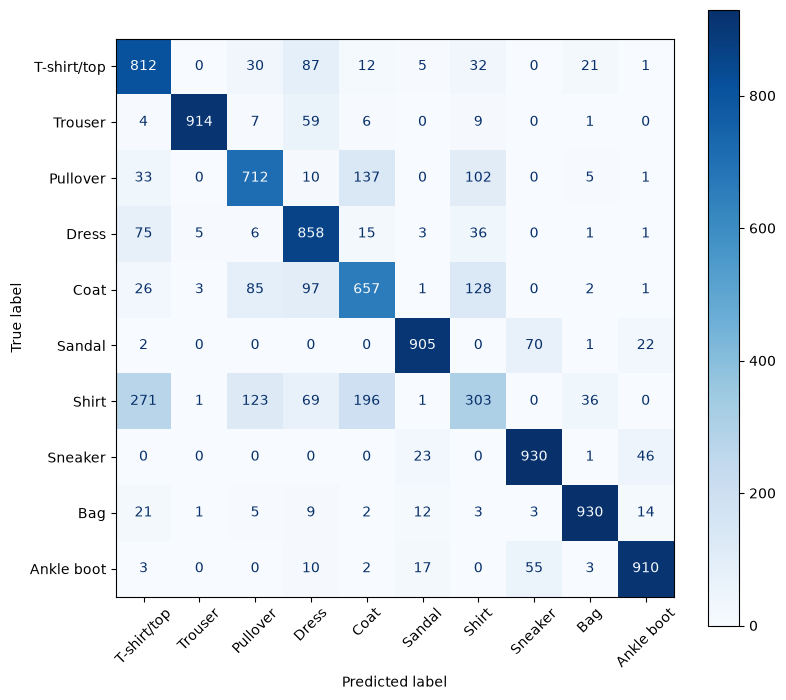

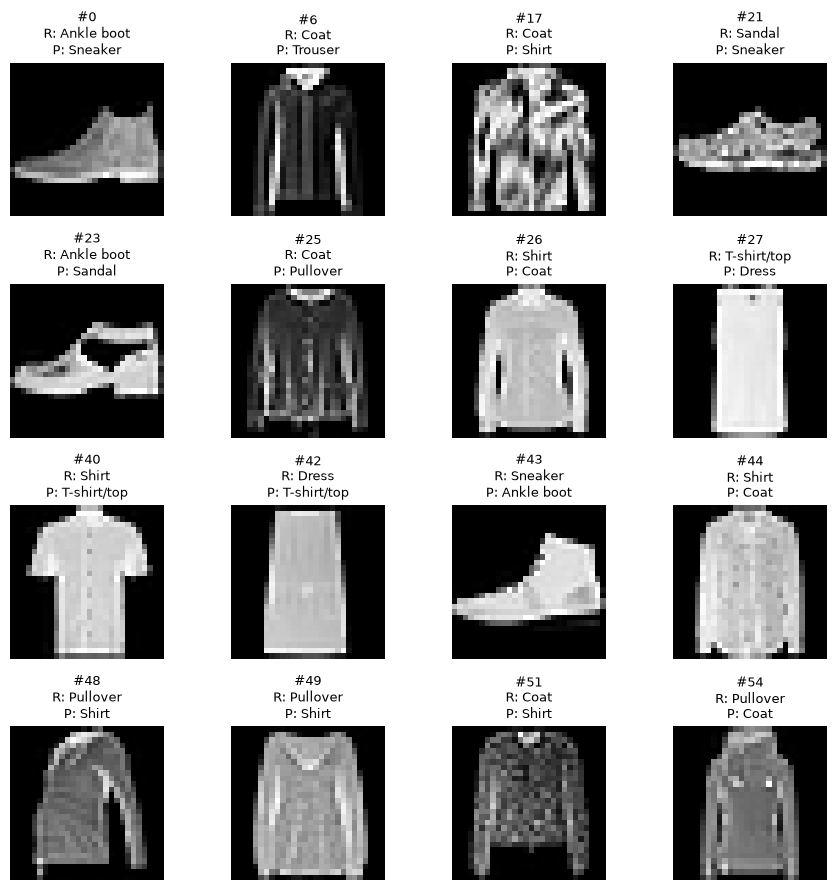

In [37]:
run()